# Purging Every Combination

The protected training set for split $s$ is:

$$
T_s^{\mathrm{safe}}
=\left\{i\notin S_s:
I_i\cap\left(\bigcup_{j\in S_s}I_j\right)=\varnothing,
\ i\notin E_s\right\}.
$$

Here, $S_s$ is the test set, $I_i$ is the information interval of observation $i$, $E_s$ is the embargoed region, and $T_s^{\mathrm{safe}}$ is the training set that remains after removing shared label time and the declared buffer.

In [1]:
import re as _table_number_re
from IPython.display import HTML as _TableHTML, display as _raw_display


def compact_float_format(number_format=None):
    def format_value(value):
        if number_format is None:
            rendered = str(value)
        elif callable(number_format):
            rendered = str(number_format(value))
        else:
            rendered = number_format % value
        return compact_numeric_token(rendered)
    return format_value


def compact_numeric_token(rendered):
    if not _table_number_re.fullmatch(r"[+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?", rendered):
        return rendered
    value = float(rendered)
    if value != 0.0 and abs(value) < 5e-13:
        return "0"
    if ("." in rendered or "e" in rendered.lower()) and value.is_integer():
        return str(int(value))
    return rendered


def compact_numeric_text(text):
    pattern = r"(?<![0-9.eE])([+-]?(?:[0-9]+(?:\.[0-9]*)?|\.[0-9]+)(?:[eE][+-]?[0-9]+)?)(?![0-9.eE])"
    return _table_number_re.sub(pattern, lambda match: compact_numeric_token(match.group(0)), text)


def compact_table_latex(latex):
    return compact_numeric_text(latex)


def _compact_table_html(value):
    frame = value.to_frame() if isinstance(value, pd.Series) else value
    html = frame._repr_html_()
    return '<div style="display:flex;justify-content:center;">' + compact_numeric_text(html) + "</div>"


def display(value):
    if isinstance(value, (pd.DataFrame, pd.Series)):
        return _raw_display(_TableHTML(_compact_table_html(value)))
    return _raw_display(value)

from pathlib import Path
from itertools import combinations
from math import comb
import sys
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm, ListedColormap
import numpy as np
import pandas as pd
from IPython.display import Image
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from book_support import ensure_dataset
import hashlib

DATA_URL = "https://data.binance.vision/data/spot/monthly/klines/BTCUSDT/1m/BTCUSDT-1m-2021-01.zip"
DATA_DIR = ROOT / "data" / "public" / "binance"
DATA_PATH = ensure_dataset(ROOT, "binance_btcusdt")
DATA_DIR.mkdir(parents=True, exist_ok=True)
assert DATA_PATH.is_file()
expected_data_hash = "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
data_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest().upper()
assert data_hash == expected_data_hash
public_columns = ["Open time", "Open", "High", "Low", "Close", "Volume", "Close time", "Quote volume", "Trades", "Buyer base volume", "Buyer quote volume", "Unused"]
raw = pd.read_csv(DATA_PATH, compression="zip", header=None, names=public_columns, nrows=None)
raw["time"] = pd.to_datetime(raw["Open time"], unit="ms", utc=True).dt.tz_convert(None)
raw = raw.rename(columns={"Close": "close", "Volume": "volume", "Quote volume": "quote_volume", "Trades": "trades"})
raw = raw.sort_values("time").drop_duplicates("time").reset_index(drop=True)

from RiskLabAI.backtest.validation import AdaptiveCombinatorialPurged, BaggedCombinatorialPurged, CombinatorialPurged, PurgedKFold

FIGURES = ROOT / "outputs" / "figures" / "17_combinatorial_purged_cross_validation"
TABLES = ROOT / "outputs" / "tables" / "17_combinatorial_purged_cross_validation"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)

minute_data = raw.set_index("time")
bars = pd.DataFrame({
    "Close": minute_data["close"].resample("15min").last(),
    "Volume": minute_data["volume"].resample("15min").sum(),
    "Quote volume": minute_data["quote_volume"].resample("15min").sum(),
    "Trades": minute_data["trades"].resample("15min").sum(),
}).dropna()
log_close = np.log(bars["Close"])
one_bar_return = log_close.diff()
feature_frame = pd.DataFrame({
    "Previous return": one_bar_return.shift(1),
    "One-hour return": log_close.diff(4).shift(1),
    "Past volatility": one_bar_return.shift(1).rolling(16).std(),
    "Log volume change": np.log1p(bars["Volume"]).diff().shift(1),
    "Log quote-volume change": np.log1p(bars["Quote volume"]).diff().shift(1),
    "Log trade-count change": np.log1p(bars["Trades"]).diff().shift(1),
})
label_horizon = 8
forward_return = (log_close.shift(-label_horizon) - log_close).rename("Forward return")
direction = forward_return.gt(0).where(forward_return.notna()).astype("Int64").rename("Direction")
end_time = bars.index.to_series().shift(-label_horizon).rename("End time")
public_frame = pd.concat([feature_frame, direction, forward_return, end_time], axis=1).dropna()
public_x = public_frame[feature_frame.columns].astype(float)
public_y = public_frame["Direction"].astype(int)
event_times = public_frame["End time"]
external_feature = public_x["Past volatility"].copy()

palette = {"background": "#FFFFFF", "axes": "#FFFFFF", "text": "#1B365D", "cyan": "#0072B2", "amber": "#C76D00", "green": "#00866A", "rose": "#B83B3B", "violet": "#A03A78", "grid": "#D9DEE5", "muted": "#5C6670"}
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": palette["background"], "axes.facecolor": palette["axes"], "axes.edgecolor": palette["text"], "axes.labelcolor": palette["text"], "axes.titlecolor": palette["text"], "xtick.color": palette["text"], "ytick.color": palette["text"], "text.color": palette["text"], "grid.color": palette["grid"], "grid.linestyle": ":", "legend.facecolor": palette["axes"], "legend.edgecolor": palette["grid"], "savefig.facecolor": palette["background"]})

def save_table(frame, stem, caption, label, float_format="%.6f", fit=True):
    frame.to_csv(TABLES / f"{stem}.csv", index=False)
    latex = compact_table_latex(frame.to_latex(index=False, escape=True, float_format=compact_float_format(float_format), caption=caption, label=label, position="H"))
    if fit:
        latex = latex.replace(r"\begin{tabular}", r"\begin{adjustbox}{max width=\textwidth}\begin{tabular}", 1).replace(r"\end{tabular}", r"\end{tabular}\end{adjustbox}", 1)
    else:
        latex = latex.replace(r"\begin{tabular}", "\\centering\n" + r"\begin{tabular}", 1)
    (TABLES / f"{stem}.tex").write_text(latex, encoding="utf-8")

def path_number(name):
    return int(name.rsplit(" ", 1)[1])

def score_path_predictions(method, predictions):
    records = []
    for name in sorted(predictions, key=path_number):
        values = np.asarray(predictions[name]).reshape(-1)
        records.append({
            "Method": method,
            "Path": path_number(name),
            "Predictions": len(values),
            "Correct predictions": int(np.sum(values == public_y.to_numpy())),
            "Accuracy": accuracy_score(public_y, values),
            "Positive prediction share": float(np.mean(values == 1)),
        })
    return pd.DataFrame(records)

class ScaledLogisticRegression(ClassifierMixin, BaseEstimator):
    def __init__(self, max_iter=1000, random_state=15):
        self.max_iter = max_iter
        self.random_state = random_state

    def fit(self, data, labels, sample_weight=None):
        self.scaler_ = StandardScaler().fit(data)
        transformed = self.scaler_.transform(data)
        self.model_ = LogisticRegression(max_iter=self.max_iter, solver="lbfgs", random_state=self.random_state)
        self.model_.fit(transformed, labels, sample_weight=sample_weight)
        self.classes_ = self.model_.classes_
        return self

    def predict(self, data):
        return self.model_.predict(self.scaler_.transform(data))

    def predict_proba(self, data):
        return self.model_.predict_proba(self.scaler_.transform(data))

def overlap_count(train_indices, test_indices, times):
    allowed = PurgedKFold.filtered_training_indices_with_embargo(times, times.iloc[test_indices], embargo_fraction=0, continous_test_times=False)
    allowed_positions = set(times.index.get_indexer(allowed.index).tolist())
    return sum(int(int(index) not in allowed_positions) for index in train_indices)

state_colors = ListedColormap([palette["muted"], palette["cyan"], palette["rose"], palette["amber"]])
state_norm = BoundaryNorm(np.arange(-0.5, 4.5, 1), state_colors.N)
plt.rcParams.update({"font.family": "Times New Roman", "font.size": 11.5, "figure.facecolor": "#FFFFFF", "axes.facecolor": "#FFFFFF", "axes.edgecolor": "#5C6670", "axes.labelcolor": "#1B365D", "axes.titlecolor": "#1B365D", "axes.titleweight": "bold", "xtick.color": "#5C6670", "ytick.color": "#5C6670", "text.color": "#1B365D", "grid.color": "#D9DEE5", "grid.linestyle": ":", "grid.linewidth": 0.8, "legend.facecolor": "#FFFFFF", "legend.edgecolor": "#D9DEE5", "legend.framealpha": 0.96, "savefig.facecolor": "#FFFFFF", "savefig.transparent": False, "savefig.dpi": 300, "pdf.fonttype": 42, "ps.fonttype": 42})
import RiskLabAI as _risklabai_release
assert _risklabai_release.__version__ == "3.2.0"


## Protected Split Composition

,Split,Test groups,Original training observations,Test observations,Removed observations,Final training observations,Overlapping retained labels
0,1,1 and 2,1967,984,37,1930,0
1,2,1 and 3,1967,984,82,1885,0
2,3,1 and 4,1967,984,82,1885,0
3,4,1 and 5,1967,984,82,1885,0
4,5,1 and 6,1968,983,45,1923,0
5,6,2 and 3,1967,984,45,1922,0
6,7,2 and 4,1967,984,90,1877,0
7,8,2 and 5,1967,984,90,1877,0
8,9,2 and 6,1968,983,53,1915,0
9,10,3 and 4,1967,984,45,1922,0


,Quantity,Value
0,Combinatorial splits,15
1,Mean original training observations,1967.333333
2,Mean test observations,983.666667
3,Mean removed observations,60
4,Smallest final training set,1877
5,Largest final training set,1960
6,Retained overlapping labels,0


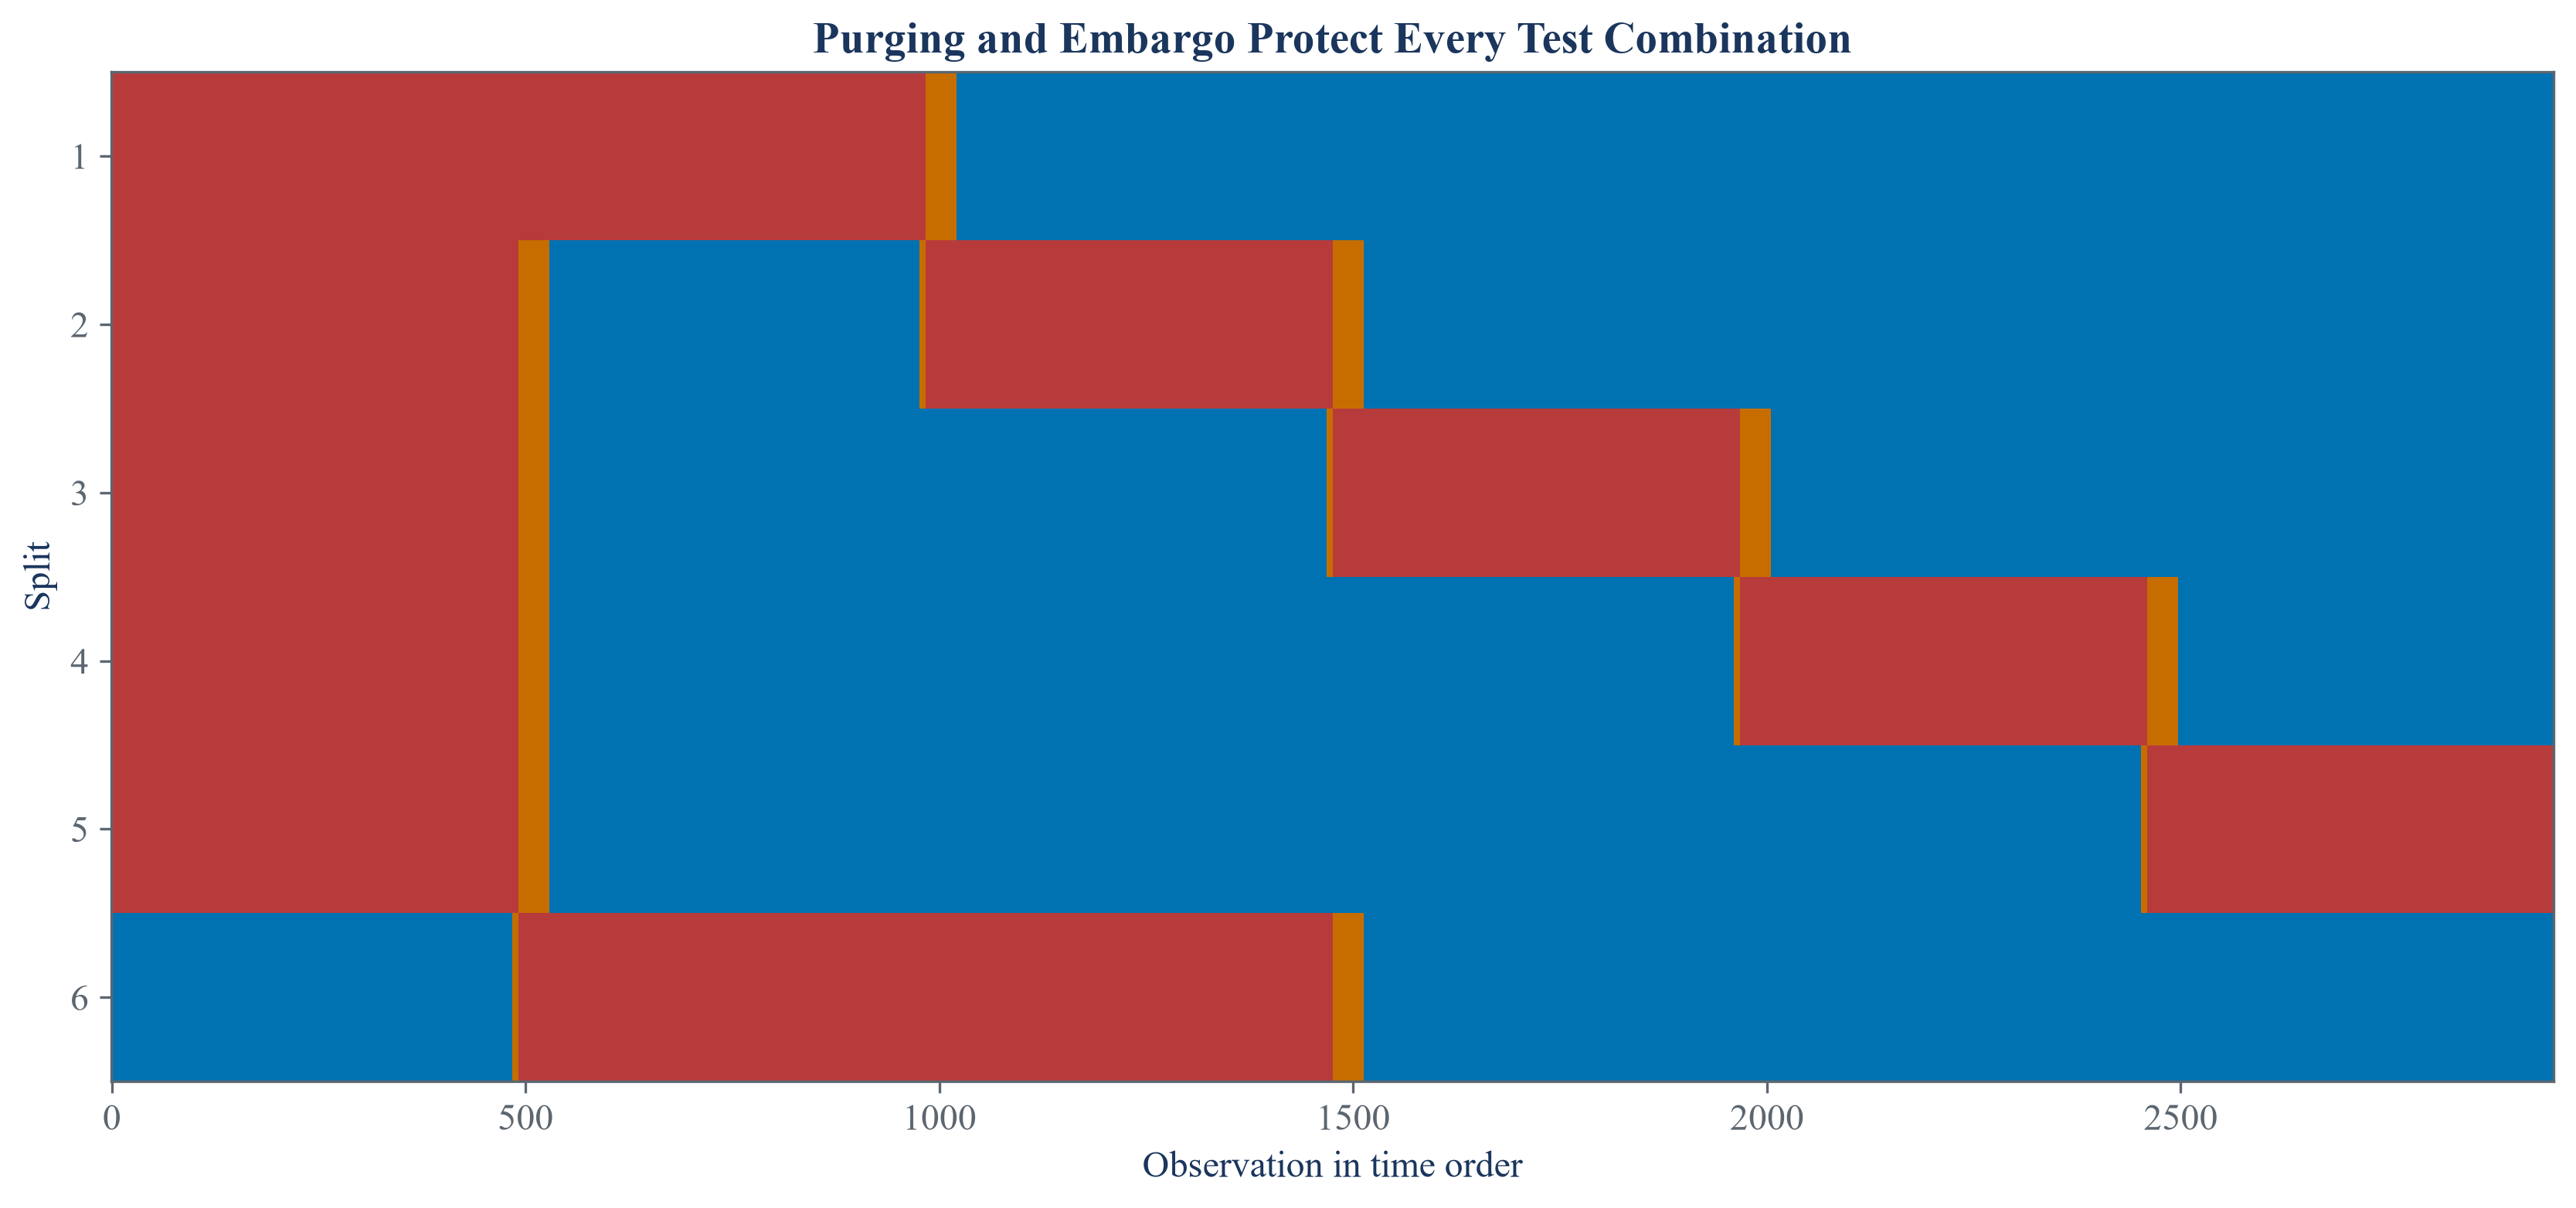

In [2]:
n_groups = 6
n_test_groups = 2
embargo_fraction = 0.01
validator = CombinatorialPurged(n_splits=n_groups, n_test_groups=n_test_groups, times=event_times, embargo=embargo_fraction)
combinations_list = list(combinations(range(n_groups), n_test_groups))
split_segments = np.array_split(np.arange(len(public_x)), n_groups)
protected_splits = list(validator.split(public_x, public_y))
split_records = []
display_matrix = np.zeros((6, len(public_x)), dtype=int)
for split_number, ((train_indices, test_indices), test_groups) in enumerate(zip(protected_splits, combinations_list), start=1):
    original_train = np.setdiff1d(np.arange(len(public_x)), test_indices)
    removed = np.setdiff1d(original_train, train_indices)
    split_records.append({
        "Split": split_number,
        "Test groups": " and ".join(str(group + 1) for group in test_groups),
        "Original training observations": len(original_train),
        "Test observations": len(test_indices),
        "Removed observations": len(removed),
        "Final training observations": len(train_indices),
        "Overlapping retained labels": overlap_count(train_indices, test_indices, event_times),
    })
    if split_number <= 6:
        display_matrix[split_number - 1, train_indices] = 1
        display_matrix[split_number - 1, test_indices] = 2
        display_matrix[split_number - 1, removed] = 3
split_composition = pd.DataFrame(split_records)
save_table(split_composition, "split_composition", "Training, testing, and removed observations across all fifteen combinatorial splits.", "tab:chapter15-split-composition")
display(split_composition)

purge_summary = pd.DataFrame({
    "Quantity": ["Combinatorial splits", "Mean original training observations", "Mean test observations", "Mean removed observations", "Smallest final training set", "Largest final training set", "Retained overlapping labels"],
    "Value": [len(split_composition), split_composition["Original training observations"].mean(), split_composition["Test observations"].mean(), split_composition["Removed observations"].mean(), split_composition["Final training observations"].min(), split_composition["Final training observations"].max(), split_composition["Overlapping retained labels"].sum()],
})
save_table(purge_summary, "purge_summary", "Summary of protected training sets for the public-data combinatorial design.", "tab:chapter15-purge-summary", fit=False)
display(purge_summary)

figure, axis = plt.subplots(figsize=(11.0, 5.1), constrained_layout=True)
axis.imshow(display_matrix, aspect="auto", interpolation="nearest", cmap=state_colors, norm=state_norm)
axis.set_title("Purging and Embargo Protect Every Test Combination")
axis.set_xlabel("Observation in time order")
axis.set_ylabel("Split")
axis.set_yticks(np.arange(6))
axis.set_yticklabels(np.arange(1, 7))
figure.savefig(FIGURES / "purge_combination_geometry.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "purge_combination_geometry.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "purge_combination_geometry.png")))
plt.close(figure)

The test-cell incidence matrix records the design before paths are assembled:

$$
A_{g,s}=\mathbf 1\{g\in C_s\},
\qquad
\sum_{s=1}^{S}A_{g,s}=\varphi(N,k).
$$

Here, $A_{g,s}$ equals one when time group $g$ is tested in split $s$, $C_s$ is the set of tested groups in that split, $S$ is the total number of splits, and $\varphi(N,k)$ is the number of complete paths.

## Joining Split Segments

,Path,Segment,Time group,Source split,Training observations,Test observations,Test begins,Test ends
0,1,1,1,1,1930,492,2021-01-01 04:15:00,2021-01-06 07:00:00
1,1,2,2,1,1930,492,2021-01-06 07:15:00,2021-01-11 10:00:00
2,1,3,3,2,1885,492,2021-01-11 10:15:00,2021-01-16 13:00:00
3,1,4,4,3,1885,492,2021-01-16 13:15:00,2021-01-21 16:00:00
4,1,5,5,4,1885,492,2021-01-21 16:15:00,2021-01-26 19:00:00
5,1,6,6,5,1923,491,2021-01-26 19:15:00,2021-01-31 21:45:00
6,2,1,1,2,1885,492,2021-01-01 04:15:00,2021-01-06 07:00:00
7,2,2,2,6,1922,492,2021-01-06 07:15:00,2021-01-11 10:00:00
8,2,3,3,6,1922,492,2021-01-11 10:15:00,2021-01-16 13:00:00
9,2,4,4,7,1877,492,2021-01-16 13:15:00,2021-01-21 16:00:00


,Path,Segments,Test observations,Mean training observations,Smallest training set,Largest training set
0,1,6,2951,1906.333333,1885,1930
1,2,6,2951,1899.666667,1877,1922
2,3,6,2951,1899.666667,1877,1922
3,4,6,2951,1899.666667,1877,1922
4,5,6,2951,1931.333333,1915,1960


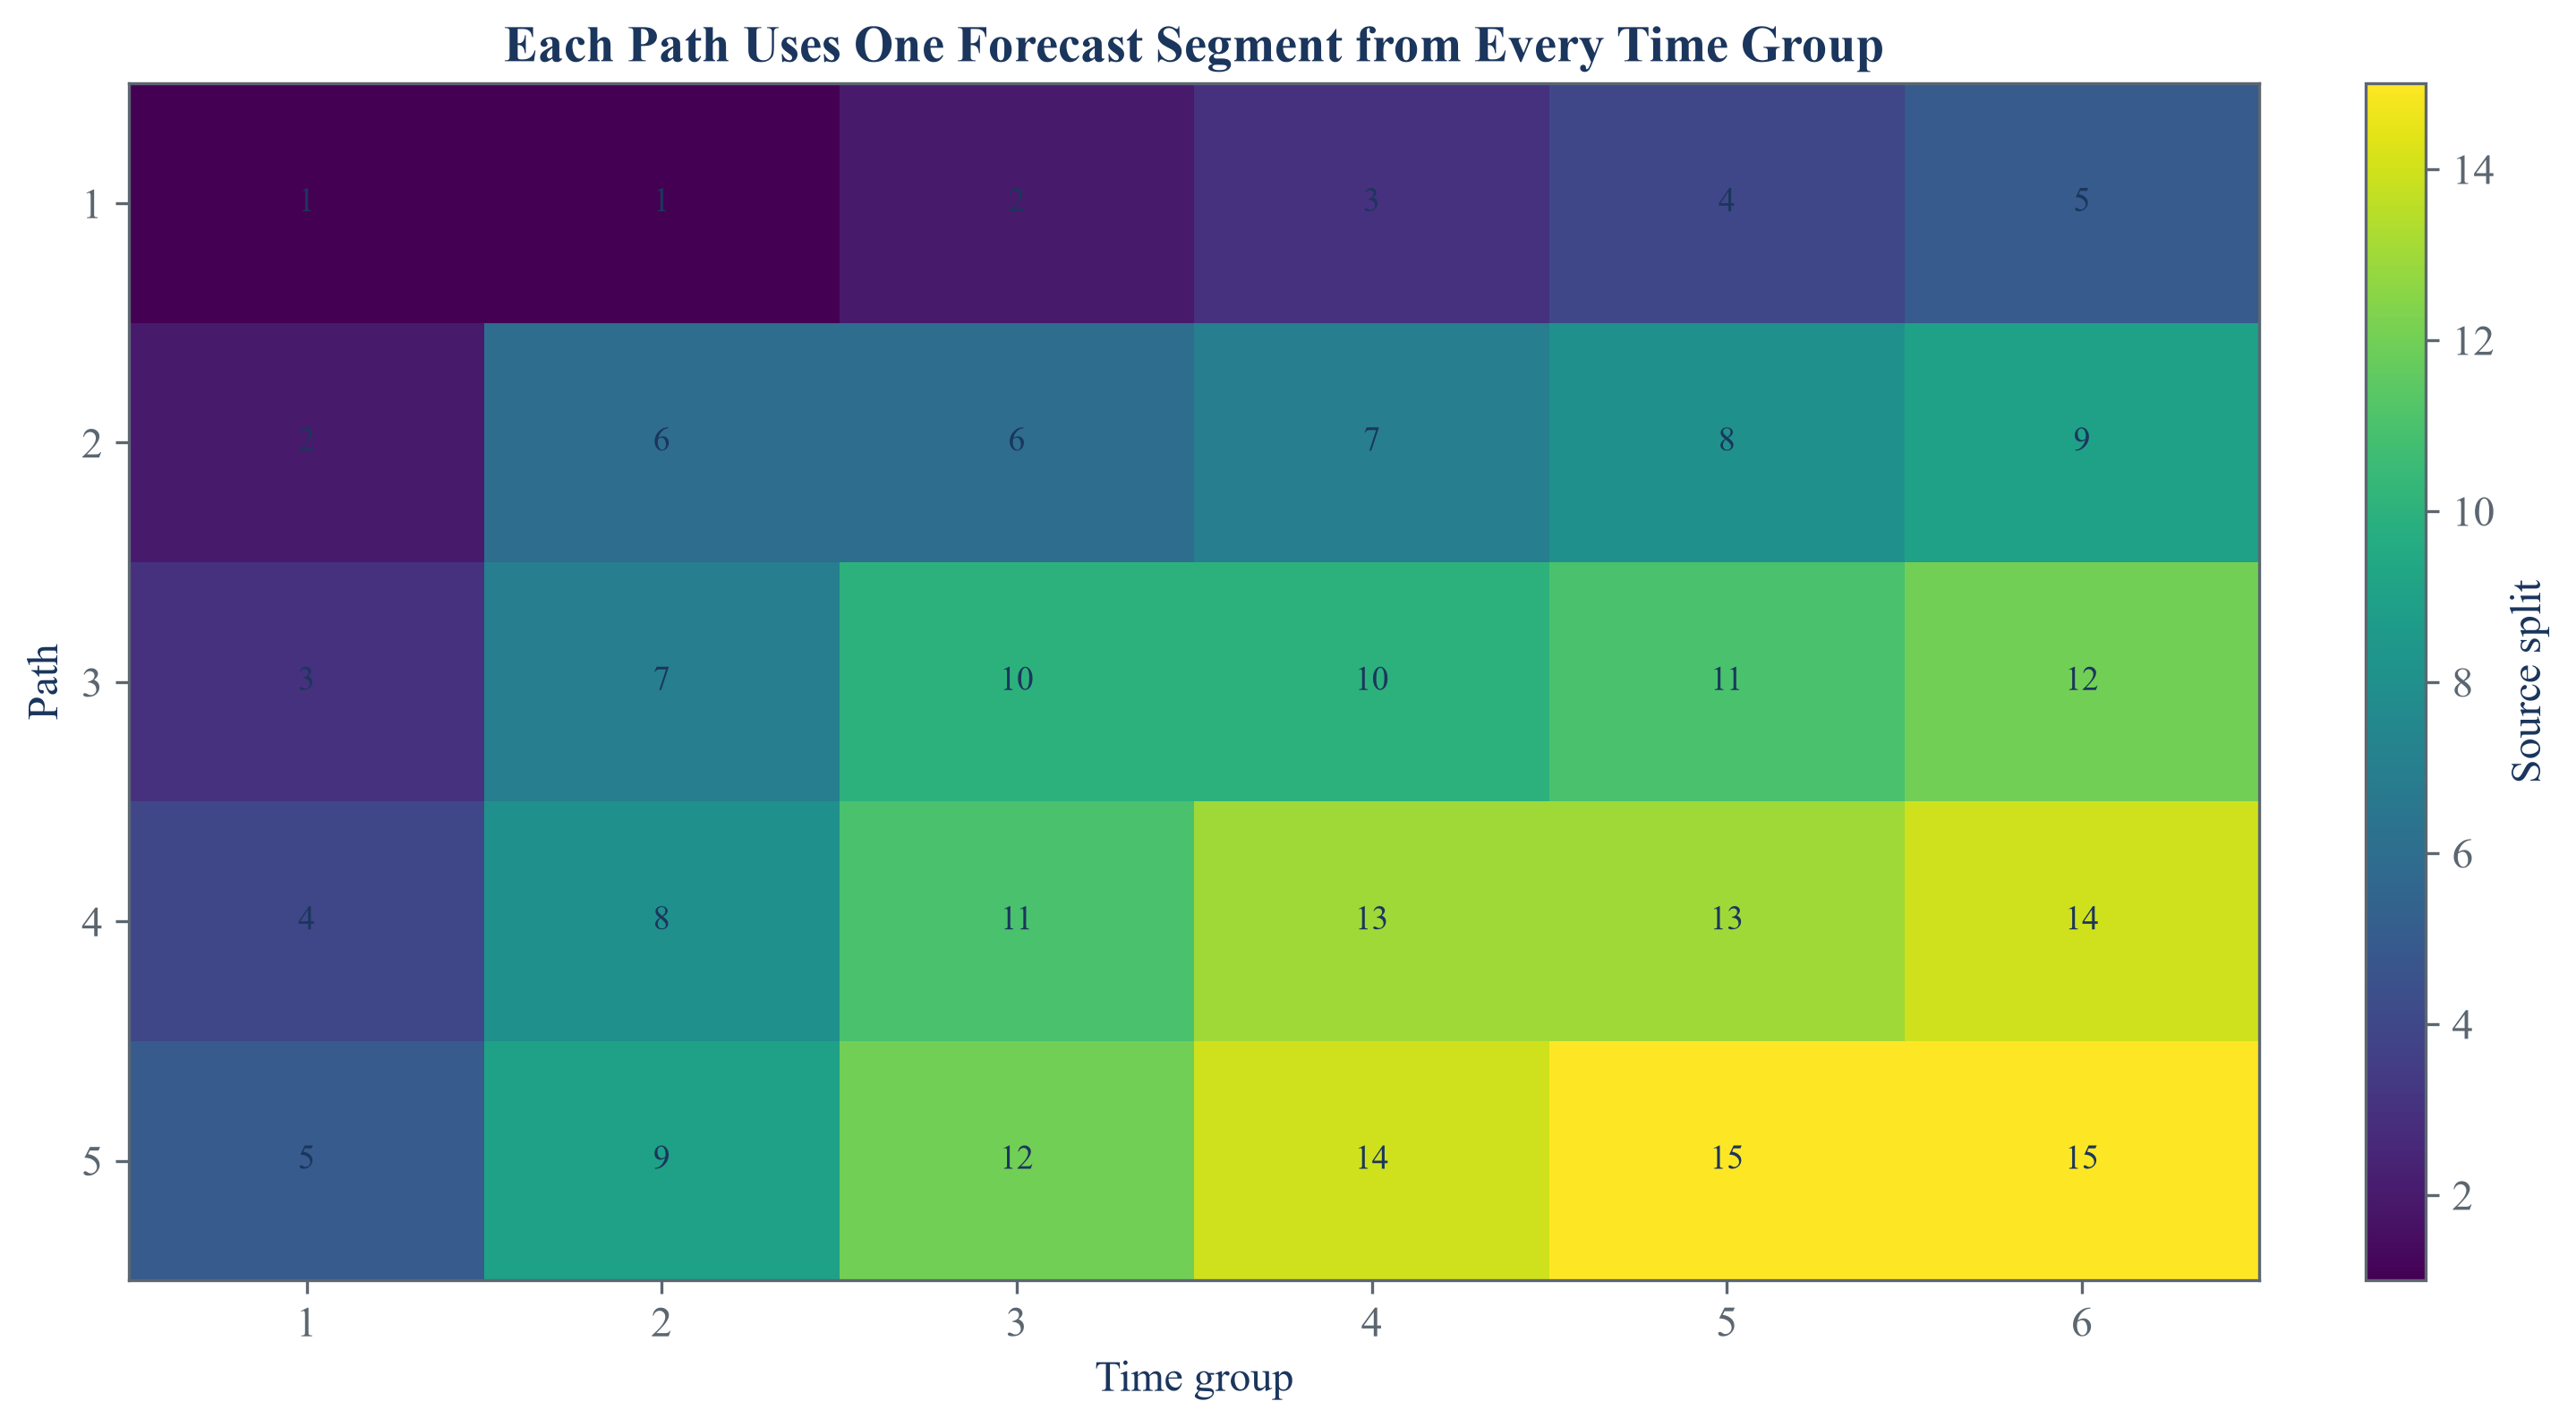

In [3]:
paths = validator.backtest_paths(public_x)
location_map = CombinatorialPurged._path_locations(n_groups, combinations_list)
segment_records = []
path_split_grid = np.zeros((len(paths), n_groups), dtype=int)
for path_name, segments in sorted(paths.items(), key=lambda item: path_number(item[0])):
    path = path_number(path_name)
    coordinates = sorted(location_map[path], key=lambda value: value[0])
    for segment_number, (segment, coordinate) in enumerate(zip(segments, coordinates), start=1):
        group_index, split_index = coordinate
        train_indices = segment["Train"]
        test_indices = segment["Test"]
        path_split_grid[path - 1, group_index] = split_index + 1
        segment_records.append({
            "Path": path,
            "Segment": segment_number,
            "Time group": group_index + 1,
            "Source split": split_index + 1,
            "Training observations": len(train_indices),
            "Test observations": len(test_indices),
            "Test begins": str(public_x.index[test_indices[0]]),
            "Test ends": str(public_x.index[test_indices[-1]]),
        })
path_segment_summary = pd.DataFrame(segment_records)
save_table(path_segment_summary, "path_segment_summary", "Source split and sample sizes for every public-data path segment.", "tab:chapter15-path-segment-summary")
display(path_segment_summary)

coverage_records = []
for path, current in path_segment_summary.groupby("Path", sort=True):
    coverage_records.append({
        "Path": path,
        "Segments": len(current),
        "Test observations": current["Test observations"].sum(),
        "Mean training observations": current["Training observations"].mean(),
        "Smallest training set": current["Training observations"].min(),
        "Largest training set": current["Training observations"].max(),
    })
path_coverage_summary = pd.DataFrame(coverage_records)
save_table(path_coverage_summary, "path_coverage_summary", "Coverage and training sizes for the five complete backtest paths.", "tab:chapter15-path-coverage-summary")
display(path_coverage_summary)

figure, axis = plt.subplots(figsize=(9.5, 5.2), constrained_layout=True)
image = axis.imshow(path_split_grid, aspect="auto", interpolation="nearest", cmap="viridis")
for row in range(path_split_grid.shape[0]):
    for column in range(path_split_grid.shape[1]):
        axis.text(column, row, str(path_split_grid[row, column]), ha="center", va="center", color=palette["text"], fontsize=9)
axis.set_title("Each Path Uses One Forecast Segment from Every Time Group")
axis.set_xlabel("Time group")
axis.set_ylabel("Path")
axis.set_xticks(np.arange(n_groups))
axis.set_xticklabels(np.arange(1, n_groups + 1))
axis.set_yticks(np.arange(len(paths)))
axis.set_yticklabels(np.arange(1, len(paths) + 1))
figure.colorbar(image, ax=axis, label="Source split")
figure.savefig(FIGURES / "path_segment_map.png", bbox_inches="tight", dpi=300)
figure.savefig(FIGURES / "path_segment_map.pdf", bbox_inches="tight")
display(Image(filename=str(FIGURES / "path_segment_map.png")))
plt.close(figure)

A complete path score averages one held-out loss for every observation:

$$
R_p=\frac{1}{T}\sum_{i=1}^{T}\ell\!\left(y_i,\widehat f_{s(p,i)}(x_i)\right).
$$

Here, $p$ identifies a backtest path, $T$ is the number of observations, $s(p,i)$ is the split that supplies observation $i$ on path $p$, $\widehat f_s$ is fitted on the protected training set of split $s$, and $\ell$ is the chosen loss.

## Embargo Sensitivity

In [4]:
embargo_records = []
for embargo in [0, 0.005, 0.01, 0.02]:
    current = CombinatorialPurged(n_splits=n_groups, n_test_groups=n_test_groups, times=event_times, embargo=embargo)
    current_splits = list(current.split(public_x, public_y))
    removals = []
    final_sizes = []
    for train_indices, test_indices in current_splits:
        original_train = np.setdiff1d(np.arange(len(public_x)), test_indices)
        removals.append(len(original_train) - len(train_indices))
        final_sizes.append(len(train_indices))
    embargo_records.append({
        "Embargo fraction": embargo,
        "Mean removed observations": float(np.mean(removals)),
        "Largest removed observations": int(max(removals)),
        "Mean final training observations": float(np.mean(final_sizes)),
        "Smallest final training set": int(min(final_sizes)),
    })
embargo_sensitivity = pd.DataFrame(embargo_records)
save_table(embargo_sensitivity, "embargo_sensitivity", "Sensitivity of combinatorial training sizes to the embargo fraction.", "tab:chapter15-embargo-sensitivity", fit=True)
display(embargo_sensitivity)

,Embargo fraction,Mean removed observations,Largest removed observations,Mean final training observations,Smallest final training set
0,0,21.333333,32,1946,1935
1,0.005,40,60,1927.333333,1907
2,0.010,60,90,1907.333333,1877
3,0.020,100,150,1867.333333,1817


## Tests

In [5]:
assert data_hash == "9364A063EFA0604D5B9D2536FB68F922DA5AFA3D8F94A26A527471A1E2F87801"
assert len(protected_splits) == 15
assert split_composition.shape == (15, 7)
assert split_composition["Overlapping retained labels"].eq(0).all()
assert (split_composition["Removed observations"] > 0).all()
assert (split_composition["Final training observations"] < split_composition["Original training observations"]).all()
assert purge_summary.shape == (7, 2)
assert len(paths) == 5
assert all(len(segments) == 6 for segments in paths.values())
assert path_segment_summary.shape == (30, 8)
assert path_coverage_summary.shape == (5, 6)
assert path_coverage_summary["Test observations"].eq(len(public_x)).all()
assert np.all(path_split_grid > 0)
assert embargo_sensitivity.shape == (4, 5)
assert embargo_sensitivity["Mean removed observations"].is_monotonic_increasing
assert embargo_sensitivity["Mean final training observations"].is_monotonic_decreasing
for train_indices, test_indices in protected_splits:
    assert overlap_count(train_indices, test_indices, event_times) == 0
assert (FIGURES / "purge_combination_geometry.pdf").is_file()
assert (FIGURES / "path_segment_map.pdf").is_file()
assert (TABLES / "split_composition.tex").is_file()
assert (TABLES / "purge_summary.tex").is_file()
assert (TABLES / "path_segment_summary.tex").is_file()
assert (TABLES / "path_coverage_summary.tex").is_file()
assert (TABLES / "embargo_sensitivity.tex").is_file()